In [9]:
# create 2 ml models (rf and xgboost) that fits monthly values of gridded features to insitu precipitation

# WORKFLOW
# 1. Load dfs and format for fiiting
# 2. Perform clusterwise ML fit
# 3. Fit and tune RF + XGB regressor using Randomized Search CV
# 4. Saved trained regressor model using joblib
# 5. Predict on test df and get accuracy metrics
# 6. Fit all clusters with single model using cluster as a feature, and save the model
# 7. Get accuracy metric for aggregate model on test df
# 8. Summarize accuracy results 

In [10]:
# LIBRARIES
import os
import numpy as np  
import pandas as pd
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

# PATHS
train_df_path = r"..\Data\Processed\RegressionModel\final_train_df.parquet"
test_df_path = r"..\Data\Processed\RegressionModel\final_test_df.parquet"
regressor_model_path = r"..\Data\Processed\RegressionModel\Saved_regressors"
regressor_metrics_path = r"..\Data\Processed\RegressionModel\validation_results"

os.makedirs(regressor_model_path, exist_ok = True)
os.makedirs(regressor_metrics_path, exist_ok = True)

# CONFIGURATIONS
random_state_num = 64
n_cores = 2
target_variable = 'insitu_monthly_total'
predictor_features = ['y', 'x', 
        'era5l_monthly_sum', 'chirps_monthly_sum', 'har_monthly_sum', 
        'persiann_monthly_sum', 'mswep_monthly_sum', 
        'chirps_wet_day_count', 'chirps_monthly_std',
        'evi_monthly_mean', 'lst_d_monthly_mean', 'lst_d_missing_fraction',
        'lst_n_monthly_mean', 'lst_n_missing_fraction', 'lst_diff_monthly_mean',
        'cluster', 'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 
        'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
        'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 'month_sin', 'month_cos']

In [11]:
# 1. Load and format dfs
train_df = pd.read_parquet(train_df_path)
test_df = pd.read_parquet(test_df_path)

cluster_list = sorted(test_df['cluster'].unique().tolist())

# Helper functions
def get_param_grids():
    param_dist_rf = {
        'n_estimators':      [50, 100, 500, 1000, 2000],
        'max_features':      ['sqrt', 'log2'],
        'max_depth':         [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf':  [1, 2, 4],
    }
    param_dist_xgb = {
        'n_estimators':     [50, 100, 500, 1000, 2000],
        'max_depth':        [3, 5, 7, 10],
        'learning_rate':    [0.01, 0.05, 0.1, 0.2],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'gamma':            [0, 0.1, 0.5],
    }
    
    return param_dist_rf, param_dist_xgb

def compute_metrics(y_true, y_pred, label):
    """Compute RMSE, MAE, R² and print with label."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f"    [{label}]  RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.4f}  n={len(y_true)}")
    return {'rmse': round(rmse, 4), 'mae': round(mae, 4), 'r2': round(r2, 4),
            'n': len(y_true)}

In [12]:
# 2. Perform clusterwise ML fit
cluster_results = []
for cluster in cluster_list:
    print(f"Processing Cluster {cluster} ----------------------------------")
    
    # 3. Fit and tune RF + XGB regressor using Randomized Search CV
    cluster_train = train_df[train_df['cluster'] == cluster].copy()
    cluster_test = test_df[test_df['cluster'] == cluster].copy()
    X_train = cluster_train[predictor_features].drop(columns = ['cluster'], errors='ignore').values
    y_train = cluster_train[target_variable].values

    param_dist_rf, param_dist_xgb = get_param_grids()

    for model_type in ['rf', 'xgb']:
        if model_type == 'rf':
            base_model = Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('reg',     RandomForestRegressor(random_state=random_state_num,
                                                  n_jobs=n_cores)),
            ])
            param_dist = {f'reg__{k}': v for k, v in param_dist_rf.items()}
        else:
            base_model = Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('reg',     XGBRegressor(random_state=random_state_num,
                                         n_jobs=n_cores,
                                         verbosity=0)),
            ])
            param_dist = {f'reg__{k}': v for k, v in param_dist_xgb.items()}
        search = RandomizedSearchCV(
            estimator=base_model,
            param_distributions=param_dist,
            n_iter=50,
            cv=5,
            verbose=1,
            random_state=random_state_num,
            n_jobs=n_cores,
            scoring='neg_root_mean_squared_error',
        )
        search.fit(X_train, y_train)
        best_model = search.best_estimator_

        print(f"\n  [Cluster {cluster} | {model_type.upper()}]")
        print(f"    Best params : {search.best_params_}")
        print(f"    CV RMSE     : {-search.best_score_:.4f}")

         # 4. Saved trained regressor model using joblib
        model_path = os.path.join(regressor_model_path, f"cluster{cluster}_{model_type}_regressor.pkl")
        joblib.dump(best_model, model_path)
        print(f"Model {model_type} saved to {model_path}")
        train_metrics = compute_metrics(y_train, best_model.predict(X_train),
                                        'Train — Validation')
        
        # 5. Predict on test df and get accuracy metrics
        X_test = cluster_test[predictor_features].drop(columns=['cluster'], errors='ignore').values
        y_test = cluster_test[target_variable].values
        y_pred = best_model.predict(X_test)
        test_metrics = compute_metrics(y_test, best_model.predict(X_test),
                                        'Test — Validation')
        cluster_results.append({
            'cluster': cluster,
            'model': model_type.upper(),
            'Train-RMSE': train_metrics['rmse'],
            'Train-MAE': train_metrics['mae'],
            'Train-R2': train_metrics['r2'],
            'Train-n': train_metrics['n'],
            'Test-RMSE': test_metrics['rmse'],
            'Test-MAE': test_metrics['mae'],
            'Test-R2': test_metrics['r2'],
            'Test-n': test_metrics['n']            
        })

results_df = pd.DataFrame(cluster_results)

avg_rows = (
    results_df.groupby('model')[
        ['Train-RMSE', 'Train-MAE', 'Train-R2',
         'Test-RMSE', 'Test-MAE',
         'Test-R2']
    ].mean().round(4).reset_index().assign(cluster='AVERAGE')
)

summary_df = pd.concat([results_df, avg_rows], ignore_index=True)
summary_df = summary_df[['cluster', 'model',
                    'Train-RMSE', 'Train-MAE', 'Train-R2',
                    'Test-RMSE', 'Test-MAE',
                    'Test-R2']]   

Processing Cluster 0.0 ----------------------------------
Fitting 5 folds for each of 50 candidates, totalling 250 fits

  [Cluster 0.0 | RF]
    Best params : {'reg__n_estimators': 500, 'reg__min_samples_split': 2, 'reg__min_samples_leaf': 1, 'reg__max_features': 'log2', 'reg__max_depth': None}
    CV RMSE     : 88.4090
Model rf saved to ..\Data\Processed\RegressionModel\Saved_regressors\cluster0.0_rf_regressor.pkl
    [Train — Validation]  RMSE=31.9329  MAE=17.5173  R²=0.9719  n=935
    [Test — Validation]  RMSE=80.8416  MAE=46.2751  R²=0.7401  n=356
Fitting 5 folds for each of 50 candidates, totalling 250 fits

  [Cluster 0.0 | XGB]
    Best params : {'reg__subsample': 1.0, 'reg__n_estimators': 1000, 'reg__max_depth': 3, 'reg__learning_rate': 0.01, 'reg__gamma': 0.1, 'reg__colsample_bytree': 0.6}
    CV RMSE     : 90.5478
Model xgb saved to ..\Data\Processed\RegressionModel\Saved_regressors\cluster0.0_xgb_regressor.pkl
    [Train — Validation]  RMSE=49.2203  MAE=31.0722  R²=0.9333  

In [13]:
# 6. Fit all clusters with single model using cluster as a feature, and save the model
X_train_all = train_df[predictor_features].values
y_train_all = train_df[target_variable].values
param_dist_rf, param_dist_xgb = get_param_grids()

aggregate_results = []
for model_type in ['rf', 'xgb']:
    if model_type == 'rf':
        base_model = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('reg',     RandomForestRegressor(random_state=random_state_num,
                                            n_jobs=n_cores)),
        ])
        param_dist = {f'reg__{k}': v for k, v in param_dist_rf.items()}
    else:
        base_model = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('reg',     XGBRegressor(random_state=random_state_num,
                                    n_jobs=n_cores,
                                    verbosity=0)),
        ])
        param_dist = {f'reg__{k}': v for k, v in param_dist_xgb.items()}
    search = RandomizedSearchCV(
        estimator=base_model,
        param_distributions=param_dist,
        n_iter=50,
        cv=5,
        verbose=1,
        random_state=random_state_num,
        n_jobs=n_cores,
        scoring='neg_root_mean_squared_error',
    )
    search.fit(X_train_all, y_train_all)
    best_model = search.best_estimator_
    model_path = os.path.join(regressor_model_path, f"Aggregated_{model_type}_regressor.pkl")
    joblib.dump(best_model, model_path)
    print(f"Model {model_type} saved to {model_path}")
    train_metrics = compute_metrics(y_train_all, best_model.predict(X_train_all), 'Train — Validation')
    
    X_test_all = test_df[predictor_features].values
    y_test_all = test_df[target_variable].values
    y_pred = best_model.predict(X_test_all)
    test_metrics = compute_metrics(y_test_all, best_model.predict(X_test_all),
                                        'Test — Validation')
    aggregate_results.append({
            'cluster': "Aggregated",
            'model': model_type.upper(),
            'Train-RMSE': train_metrics['rmse'],
            'Train-MAE': train_metrics['mae'],
            'Train-R2': train_metrics['r2'],
            'Train-n': train_metrics['n'],
            'Test-RMSE': test_metrics['rmse'],
            'Test-MAE': test_metrics['mae'],
            'Test-R2': test_metrics['r2'],
            'Test-n': test_metrics['n']            
    })           

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Model rf saved to ..\Data\Processed\RegressionModel\Saved_regressors\Aggregated_rf_regressor.pkl
    [Train — Validation]  RMSE=39.7384  MAE=20.8356  R²=0.9536  n=2886
    [Test — Validation]  RMSE=90.3968  MAE=49.3920  R²=0.7829  n=1035
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Model xgb saved to ..\Data\Processed\RegressionModel\Saved_regressors\Aggregated_xgb_regressor.pkl
    [Train — Validation]  RMSE=45.1728  MAE=28.8480  R²=0.9400  n=2886
    [Test — Validation]  RMSE=95.0341  MAE=52.3767  R²=0.7601  n=1035


In [14]:
# 8. Summarize accuracy results
aggregate_df = pd.DataFrame(aggregate_results)

# Combine cluster results, average rows, and aggregate model results
final_summary_df = pd.concat([summary_df, aggregate_df], ignore_index=True)

# Display the final summary
display(final_summary_df)

# Save to CSV
csv_path = os.path.join(regressor_metrics_path, "monthly_regression_metrics_summary.csv")
final_summary_df.to_csv(csv_path, index=False)
print(f"\nAccuracy validation results saved to {csv_path}")


,cluster,model,Train-RMSE,Train-MAE,Train-R2,Test-RMSE,Test-MAE,Test-R2,Train-n,Test-n
0,0.0,RF,31.9329,17.5173,0.9719,80.8416,46.2751,0.7401,NaN,NaN
1,0.0,XGB,49.2203,31.0722,0.9333,85.5730,48.6332,0.7088,NaN,NaN
2,1.0,RF,25.5207,14.4713,0.9836,87.7872,49.8564,0.8437,NaN,NaN
3,1.0,XGB,44.1273,28.3129,0.9509,86.3579,50.9575,0.8487,NaN,NaN
4,2.0,RF,30.5208,15.2721,0.9687,104.1350,51.0839,0.7568,NaN,NaN
5,2.0,XGB,27.1401,17.8777,0.9753,116.9488,55.4145,0.6933,NaN,NaN
6,3.0,RF,13.3089,7.8456,0.9621,114.0972,65.0163,0.3357,NaN,NaN
7,3.0,XGB,0.2339,0.1451,1.0000,113.2825,64.8909,0.3451,NaN,NaN
8,AVERAGE,RF,25.3208,13.7766,0.9716,96.7152,53.0579,0.6691,NaN,NaN
9,AVERAGE,XGB,30.1804,19.3520,0.9649,100.5406,54.9740,0.6490,NaN,NaN



Accuracy validation results saved to ..\Data\Processed\RegressionModel\validation_results\monthly_regression_metrics_summary.csv


In [15]:
# Fair comparison: global model evaluated per cluster vs stratified model
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

CLUSTER_NAMES = {0.0: '0', 1.0: '1', 2.0: '2', 3.0: '3'}

train_df = pd.read_parquet(train_df_path)
test_df  = pd.read_parquet(test_df_path)

predictor_features_no_cluster = [f for f in predictor_features if f != 'cluster']

comparison_results = []

for model_type in ['RF', 'XGB']:
    mt = model_type.lower()
    global_model = joblib.load(f"{regressor_model_path}/Aggregated_{mt}_regressor.pkl")
    
    model_rows = []
    for cluster in sorted(test_df['cluster'].dropna().unique()):
        cname  = CLUSTER_NAMES.get(cluster, f"Cluster {cluster}")
        ctest  = test_df[test_df['cluster'] == cluster]
        y_true = ctest[target_variable].values

        # Global model — evaluated on this cluster's rows only
        X_glob   = ctest[predictor_features].values
        r2_glob  = r2_score(y_true, global_model.predict(X_glob))

        # Stratified model — same cluster rows
        strat_model = joblib.load(f"{regressor_model_path}/cluster{cluster}_{mt}_regressor.pkl")
        X_strat     = ctest[predictor_features_no_cluster].values
        r2_strat    = r2_score(y_true, strat_model.predict(X_strat))

        delta   = r2_strat - r2_glob
        verdict = '→ STRATIFY' if delta > 0.01 else ('→ GLOBAL' if delta < -0.01 else '≈ EQUAL')
        
        row = {
            'Model': model_type,
            'Cluster': cname,
            'N_test': len(ctest),
            'R2_stratified': round(r2_strat, 4),
            'R2_global_here': round(r2_glob, 4),
            'Delta': round(delta, 4),
            'Verdict': verdict
        }
        model_rows.append(row)
    
    # Calculate average row for this model
    avg_r2_strat = np.mean([r['R2_stratified'] for r in model_rows])
    avg_r2_glob  = np.mean([r['R2_global_here'] for r in model_rows])
    avg_delta    = avg_r2_strat - avg_r2_glob
    
    avg_row = {
        'Model': model_type,
        'Cluster': 'AVERAGE',
        'N_test': sum([r['N_test'] for r in model_rows]),
        'R2_stratified': round(avg_r2_strat, 4),
        'R2_global_here': round(avg_r2_glob, 4),
        'Delta': round(avg_delta, 4),
        'Verdict': '-'
    }
    model_rows.append(avg_row)
    comparison_results.extend(model_rows)

# Convert to DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Display result
display(comparison_df)

# Save to CSV
csv_path = os.path.join(regressor_metrics_path, "stratified_vs_global_comparison.csv")
comparison_df.to_csv(csv_path, index=False)
print(f"\nComparison results saved to {csv_path}")


,Model,Cluster,N_test,R2_stratified,R2_global_here,Delta,Verdict
0,RF,0,356,0.7401,0.7774,-0.0373,→ GLOBAL
1,RF,1,383,0.8437,0.8213,0.0224,→ STRATIFY
2,RF,2,180,0.7568,0.7604,-0.0036,≈ EQUAL
3,RF,3,116,0.3357,0.4865,-0.1508,→ GLOBAL
4,RF,AVERAGE,1035,0.6691,0.7114,-0.0423,-
5,XGB,0,356,0.7088,0.7201,-0.0113,→ GLOBAL
6,XGB,1,383,0.8487,0.7970,0.0517,→ STRATIFY
7,XGB,2,180,0.6933,0.7884,-0.0951,→ GLOBAL
8,XGB,3,116,0.3451,0.4234,-0.0783,→ GLOBAL
9,XGB,AVERAGE,1035,0.6490,0.6822,-0.0333,-



Comparison results saved to ..\Data\Processed\RegressionModel\validation_results\stratified_vs_global_comparison.csv


In [16]:
# %%
# =============================================================================
# Permutation Feature Importance — Individual + Category Level
# Evaluated on test set (spatially blocked) to avoid train overfitting artefact.
# Two CSVs saved:
#   1. perm_importance_individual.csv  — per feature per model
#   2. perm_importance_category.csv    — block-permuted per category per model
#
# Block permutation for categories: all features in a group are shuffled
# simultaneously. This captures the joint contribution of the group and
# avoids underestimation caused by correlated features compensating
# for each other when permuted individually.
# =============================================================================

from sklearn.inspection import permutation_importance
import numpy as np
import pandas as pd
import joblib
import os

N_REPEATS   = 10    # repeats per permutation — higher = more stable estimate
RANDOM_SEED = 64
MODEL_TYPE  = 'RF'  # global model used for importance analysis

# ── Feature category definitions ─────────────────────────────────────────────
# Each category is permuted as a block for the category-level analysis.

FEATURE_CATEGORIES = {
    'Precipitation_sums':    ['era5l_monthly_sum', 'chirps_monthly_sum',
                               'har_monthly_sum', 'persiann_monthly_sum', 
                               'mswep_monthly_sum', 'era5l_k_monthly_sum'],
    'CHIRPS_prec_diagnostics':['chirps_wet_day_count', 'chirps_monthly_std'],
    'MODIS_EVI':             ['evi_monthly_mean'],
    'MODIS_LST':             ['lst_d_monthly_mean', 'lst_d_missing_fraction',
                               'lst_n_monthly_mean', 'lst_n_missing_fraction',
                               'lst_diff_monthly_mean'],
    'Topographic':           ['elev_mean', 'elev_std', 'elev_max', 'elev_min',
                               'slope_mean', 'aspect_mean', 'elev_smoothed',
                               'local_relief'],
    'Fetch':                 ['fetch_1000m_dist', 'fetch_1000m_dir',
                               'fetch_500m_dist', 'fetch_500m_dir'],
    'Spatial':               ['y', 'x'],
    'Temporal':              ['month_sin', 'month_cos'],
    'Cluster':               ['cluster'],
}

# ── Load data and models ──────────────────────────────────────────────────────

train_df = pd.read_parquet(train_df_path)
test_df  = pd.read_parquet(test_df_path)

X_test = test_df[predictor_features].values
y_test = test_df[target_variable].values

# ── Helper: assign category label to each feature ────────────────────────────

feature_to_category = {}
for cat, feats in FEATURE_CATEGORIES.items():
    for f in feats:
        if f in predictor_features:
            feature_to_category[f] = cat

# ── 1. Individual permutation importance ─────────────────────────────────────

individual_rows = []

model = joblib.load(os.path.join(regressor_model_path,
                                 f"Aggregated_{MODEL_TYPE.lower()}_regressor.pkl"))

perm = permutation_importance(
    model, X_test, y_test,
    n_repeats=N_REPEATS,
    random_state=RANDOM_SEED,
    n_jobs=n_cores,
    scoring='r2'
)

for i, feat in enumerate(predictor_features):
    individual_rows.append({
        'model':            MODEL_TYPE,
        'feature':          feat,
        'category':         feature_to_category.get(feat, 'Other'),
        'importance_mean':  round(perm.importances_mean[i], 6),
        'importance_std':   round(perm.importances_std[i],  6),
    })

individual_df = (
    pd.DataFrame(individual_rows)
    .sort_values('importance_mean', ascending=False)
    .reset_index(drop=True)
)
individual_df['rank'] = individual_df['importance_mean'].rank(
    ascending=False, method='min').astype(int)

individual_df = individual_df[['model', 'rank', 'feature', 'category',
                                'importance_mean', 'importance_std']]

display(individual_df)

csv_individual = os.path.join(regressor_metrics_path, "perm_importance_individual.csv")
individual_df.to_csv(csv_individual, index=False)
print(f"Saved: {csv_individual}")

,model,rank,feature,category,importance_mean,importance_std
0,RF,1,chirps_monthly_sum,Precipitation_sums,0.128395,0.004640
1,RF,2,era5l_monthly_sum,Precipitation_sums,0.060693,0.004027
2,RF,3,mswep_monthly_sum,Precipitation_sums,0.046038,0.002373
3,RF,4,persiann_monthly_sum,Precipitation_sums,0.044099,0.002236
4,RF,5,lst_d_missing_fraction,MODIS_LST,0.033205,0.002938
5,RF,6,chirps_monthly_std,CHIRPS_prec_diagnostics,0.029388,0.001715
6,RF,7,lst_n_missing_fraction,MODIS_LST,0.021291,0.001964
7,RF,8,chirps_wet_day_count,CHIRPS_prec_diagnostics,0.020710,0.001471
8,RF,9,har_monthly_sum,Precipitation_sums,0.005463,0.000782
9,RF,10,month_cos,Temporal,0.004942,0.000812


Saved: ..\Data\Processed\RegressionModel\validation_results\perm_importance_individual.csv


In [17]:
# ── 2. Category-level block permutation importance ────────────────────────────
# Permute all features in a category simultaneously in each repeat.
# Captures joint contribution — avoids collinear compensation artefact.

category_rows = []

model = joblib.load(os.path.join(regressor_model_path,
                                 f"Aggregated_{MODEL_TYPE.lower()}_regressor.pkl"))
baseline_r2 = r2_score(y_test, model.predict(X_test))

for cat_name, cat_features in FEATURE_CATEGORIES.items():

    cat_features_present = [f for f in cat_features if f in predictor_features]
    if not cat_features_present:
        continue

    cat_indices = [predictor_features.index(f) for f in cat_features_present]

    repeat_scores = []
    rng = np.random.default_rng(RANDOM_SEED)

    for _ in range(N_REPEATS):
        X_permuted = X_test.copy()
        perm_idx = rng.permutation(len(X_permuted))
        X_permuted[:, cat_indices] = X_permuted[perm_idx][:, cat_indices]
        permuted_r2 = r2_score(y_test, model.predict(X_permuted))
        repeat_scores.append(permuted_r2)

    drop_mean = baseline_r2 - np.mean(repeat_scores)
    drop_std  = np.std(repeat_scores)

    category_rows.append({
        'model':             MODEL_TYPE,
        'category':          cat_name,
        'n_features':        len(cat_features_present),
        'features':          ', '.join(cat_features_present),
        'baseline_r2':       round(baseline_r2, 6),
        'importance_mean':   round(drop_mean,    6),
        'importance_std':    round(drop_std,      6),
    })

category_df = (
    pd.DataFrame(category_rows)
    .sort_values('importance_mean', ascending=False)
    .reset_index(drop=True)
)
category_df['rank'] = category_df['importance_mean'].rank(
    ascending=False, method='min').astype(int)

category_df = category_df[['model', 'rank', 'category', 'n_features',
                             'importance_mean', 'importance_std',
                             'baseline_r2', 'features']]

display(category_df)

csv_category = os.path.join(regressor_metrics_path, "perm_importance_category.csv")
category_df.to_csv(csv_category, index=False)
print(f"Saved: {csv_category}")

,model,rank,category,n_features,importance_mean,importance_std,baseline_r2,features
0,RF,1,Precipitation_sums,5,0.702051,0.020922,0.782924,"era5l_monthly_sum, chirps_monthly_sum, har_mon..."
1,RF,2,MODIS_LST,5,0.073566,0.006428,0.782924,"lst_d_monthly_mean, lst_d_missing_fraction, ls..."
2,RF,3,CHIRPS_prec_diagnostics,2,0.059894,0.004500,0.782924,"chirps_wet_day_count, chirps_monthly_std"
3,RF,4,Topographic,8,0.010027,0.005041,0.782924,"elev_mean, elev_std, elev_max, elev_min, slope..."
4,RF,5,Temporal,2,0.009670,0.001270,0.782924,"month_sin, month_cos"
5,RF,6,MODIS_EVI,1,-0.000114,0.001080,0.782924,evi_monthly_mean
6,RF,7,Cluster,1,-0.000427,0.000629,0.782924,cluster
7,RF,8,Fetch,4,-0.000459,0.000821,0.782924,"fetch_1000m_dist, fetch_1000m_dir, fetch_500m_..."
8,RF,9,Spatial,2,-0.002758,0.002032,0.782924,"y, x"


Saved: ..\Data\Processed\RegressionModel\validation_results\perm_importance_category.csv


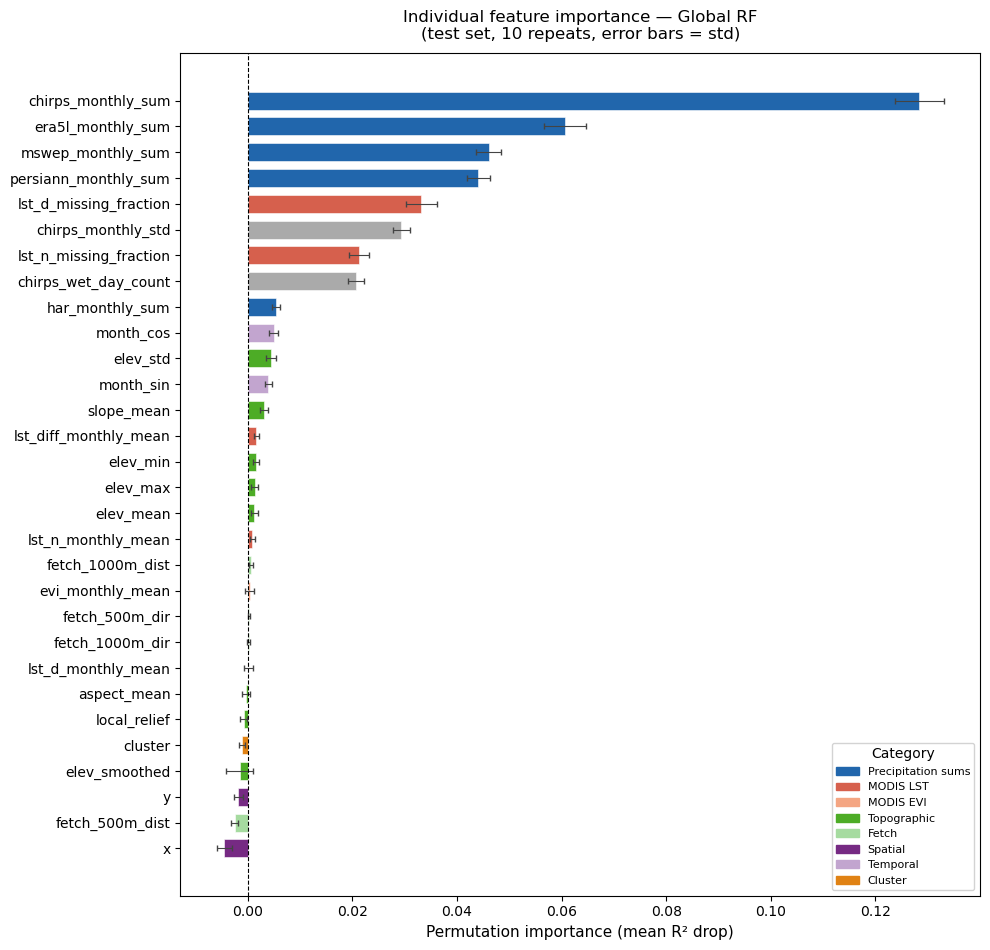

Saved: ..\Data\Processed\RegressionModel\validation_results\plots\perm_importance_individual.png


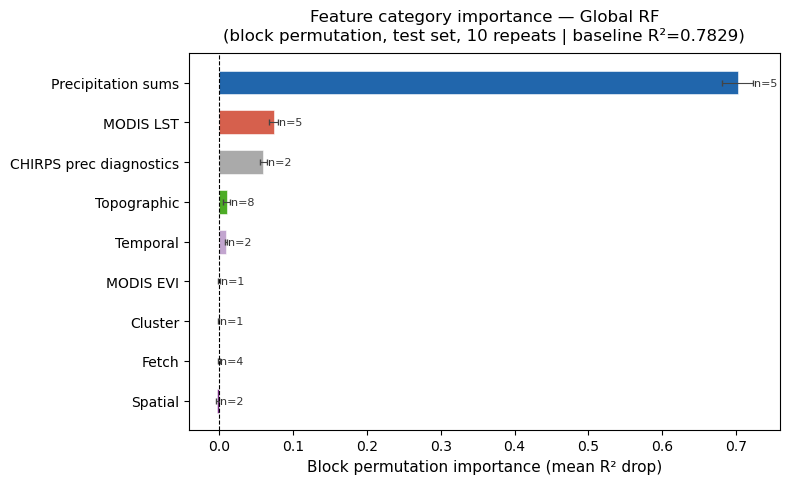

Saved: ..\Data\Processed\RegressionModel\validation_results\plots\perm_importance_category.png

── Spearman correlation flags (|r| > 0.85, individual importance caveat) ──
           feature_a            feature_b  spearman_r
           elev_mean             elev_min    0.989330
           elev_mean             elev_max    0.974727
  chirps_monthly_sum   chirps_monthly_std    0.964684
            elev_max             elev_min    0.962792
  chirps_monthly_sum persiann_monthly_sum    0.934145
                   y                    x    0.914196
   era5l_monthly_sum persiann_monthly_sum    0.897003
     har_monthly_sum persiann_monthly_sum    0.890385
persiann_monthly_sum   chirps_monthly_std    0.889420
            elev_std           slope_mean    0.883746
   era5l_monthly_sum   chirps_monthly_sum    0.880766
   era5l_monthly_sum      har_monthly_sum    0.874266
persiann_monthly_sum    mswep_monthly_sum    0.869987
  chirps_monthly_sum      har_monthly_sum    0.868507
  chirps_monthly_s

In [18]:
# ── 3. Quick collinearity note printed alongside importance ───────────────────
# Individual importances for correlated features understate their joint value.
# Flag feature pairs with Spearman |r| > 0.85 for the methods section.

# %%
# =============================================================================
# Bar plot visualisation — Individual and Category permutation importance
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

diag_out_dir = os.path.join(regressor_metrics_path, "plots")
os.makedirs(diag_out_dir, exist_ok=True)

# Colour palette — one colour per category, consistent across both plots
CATEGORY_COLORS = {
    'Precipitation_sums':     '#2166AC',
    'ERA5L_prec_diagnostics': '#4393C3',
    'ERA5L_met':              '#74ADD1',
    'MODIS_LST':              '#D6604D',
    'MODIS_EVI':              '#F4A582',
    'Topographic':            '#4DAC26',
    'Fetch':                  '#A6DBA0',
    'Spatial':                '#762A83',
    'Temporal':               '#C2A5CF',
    'Cluster':                '#E08214',
}

# ── Plot 1 — Individual feature importance ────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, max(6, len(individual_df) * 0.32)))

colors = [CATEGORY_COLORS.get(cat, '#AAAAAA')
          for cat in individual_df['category']]

bars = ax.barh(
    individual_df['feature'],
    individual_df['importance_mean'],
    xerr=individual_df['importance_std'],
    color=colors,
    edgecolor='white',
    linewidth=0.4,
    error_kw=dict(elinewidth=0.8, ecolor='#444444', capsize=2),
    height=0.7,
)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Permutation importance (mean R² drop)', fontsize=11)
ax.set_title(f'Individual feature importance — Global {MODEL_TYPE}\n'
             f'(test set, {N_REPEATS} repeats, error bars = std)',
             fontsize=12, pad=10)
ax.invert_yaxis()

# Legend for categories
legend_handles = [
    mpatches.Patch(color=c, label=cat.replace('_', ' '))
    for cat, c in CATEGORY_COLORS.items()
    if cat in individual_df['category'].values
]
ax.legend(handles=legend_handles, fontsize=8, loc='lower right',
          framealpha=0.85, title='Category')

plt.tight_layout()
plot1_path = os.path.join(diag_out_dir, "perm_importance_individual.png")
fig.savefig(plot1_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {plot1_path}")

# ── Plot 2 — Category block importance ───────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, max(4, len(category_df) * 0.55)))

cat_colors = [CATEGORY_COLORS.get(cat, '#AAAAAA')
              for cat in category_df['category']]

ax.barh(
    category_df['category'].str.replace('_', ' '),
    category_df['importance_mean'],
    xerr=category_df['importance_std'],
    color=cat_colors,
    edgecolor='white',
    linewidth=0.4,
    error_kw=dict(elinewidth=0.8, ecolor='#444444', capsize=2),
    height=0.6,
)

# Annotate n_features on each bar
for i, (_, row) in enumerate(category_df.iterrows()):
    ax.text(
        max(row['importance_mean'] + row['importance_std'] + 0.001, 0.001),
        i,
        f"n={row['n_features']}",
        va='center', fontsize=8, color='#333333'
    )

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Block permutation importance (mean R² drop)', fontsize=11)
ax.set_title(f'Feature category importance — Global {MODEL_TYPE}\n'
             f'(block permutation, test set, {N_REPEATS} repeats | '
             f'baseline R²={category_df["baseline_r2"].iloc[0]:.4f})',
             fontsize=12, pad=10)
ax.invert_yaxis()

plt.tight_layout()
plot2_path = os.path.join(diag_out_dir, "perm_importance_category.png")
fig.savefig(plot2_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {plot2_path}")

# ── Collinearity note ─────────────────────────────────────────────────────────
print("\n── Spearman correlation flags (|r| > 0.85, individual importance caveat) ──")
X_df = test_df[predictor_features]
corr = X_df.corr(method='spearman').abs()
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_a', 'level_1': 'feature_b', 0: 'spearman_r'})
    .query('spearman_r > 0.85')
    .sort_values('spearman_r', ascending=False)
    .reset_index(drop=True)
)
if pairs.empty:
    print("  No pairs above threshold.")
else:
    print(pairs.to_string(index=False))
    pairs.to_csv(os.path.join(regressor_metrics_path,
                              "correlated_feature_pairs.csv"), index=False)
    print(f"\n  Saved: correlated_feature_pairs.csv")
    print("  → For these pairs, refer to category importance for joint contribution.")